# 01 — From Prediction to Decision

Projects #1 and #2 answer *"what is the machine's condition?"* — fault states, RUL in cycles. But a maintenance planner doesn't need a number; they need a **decision**: replace now, inspect at the next window, or keep operating.

This notebook builds the bridge:

1. **The cost model** — normalized, assumption-labeled; only ratios matter.
2. **The decision rule** — from expected cost: act when `p(fail) > 1/k`.
3. **Honest uncertainty** — failure probability from the *observed* residual distribution of project #2, not an assumed Gaussian.
4. **The fault-state decision table** — project #1 outputs mapped to actions.

> Every cost figure here is an **assumed parameter** (labeled as such). The framework is real; the numbers are illustrative.

In [1]:
import os, sys
# find repo root (dir containing src/) walking up from cwd
_d = os.getcwd()
while not os.path.isdir(os.path.join(_d, "src")) and _d != os.path.dirname(_d):
    _d = os.path.dirname(_d)
sys.path.insert(0, _d)
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
from src.costs import MaintenanceCosts, SCENARIOS
from src.rul_decisions import RULDecisionEngine
from src.fault_decisions import DECISION_TABLE, decide
from src.inputs import load_rul_backtest
print("cost scenarios:")
for name, c in SCENARIOS.items():
    print(f"  {name:12s}: {c.describe()}")

cost scenarios:
  conservative: planned=1.0, unplanned=3.0 (k=3.0), inspection=0.15, lead_time=1
  baseline    : planned=1.0, unplanned=5.0 (k=5.0), inspection=0.1, lead_time=1
  severe      : planned=1.0, unplanned=10.0 (k=10.0), inspection=0.05, lead_time=1


## Q1 — What does a maintenance decision actually cost?

**Why it matters.** Every 'AI for maintenance' pitch eventually meets the same question from the planner: *what do we pay if we're wrong?* Two wrongs exist: acting too early (wasted healthy life, unnecessary shop visit) and acting too late (unplanned failure). They cost different amounts — usually by a large factor.

**Method.** Normalize planned intervention to 1.0. The only parameter that matters for the *decision* is `k = unplanned / planned` (industry rule of thumb: 3–10x). Inspection is a fraction of planned. All are labeled assumptions.

In [2]:
c = SCENARIOS["baseline"]
print("Baseline:", c.describe())
print(f"\nUnplanned failure costs {c.unplanned_multiplier}x a planned visit.")
print("An inspection costs 10% of a planned visit.")

Baseline: planned=1.0, unplanned=5.0 (k=5.0), inspection=0.1, lead_time=1

Unplanned failure costs 5.0x a planned visit.
An inspection costs 10% of a planned visit.


### Interpretation

The normalization is deliberate: a planner in aviation (k≈10) and a planner in manufacturing (k≈3) get *different optimal decisions from the same model*. The model predicts physics; the cost model decides policy. Conflating the two is how pilot projects die — 'the model works but nobody acts on it' usually means the decision threshold was never derived from costs.

### Decision
Fix three scenarios (k = 3 / 5 / 10) and carry them through the whole project. No single 'true' k exists; sensitivity over k *is* the analysis.

## Q2 — When should we intervene? Deriving the rule

**Why it matters.** A threshold like 'act when RUL < 30' is usually folklore. We can do better: derive it from expected cost.

**Method.** Let p = P(true RUL < horizon | predicted RUL). Expected cost of waiting one more horizon: `p × C_u`. Cost of acting now: `C_p`. Act when `p × C_u > C_p`, i.e. **`p > 1/k`**. For k=5: act when failure risk exceeds 20%. The threshold is not a tuning knob — it falls out of the economics.

loaded 20 validation engines, 3524 residuals in 17s
residual (pred - true): mean=-0.56, std=13.87


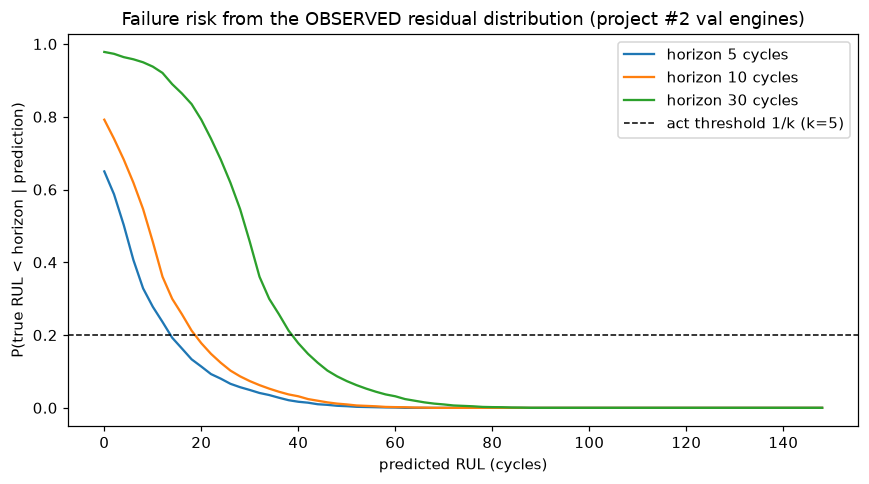

saved 01_risk_curves.png


In [3]:
import time
t0 = time.time()
engines, residuals = load_rul_backtest()
print(f"loaded {len(engines)} validation engines, {len(residuals)} residuals in {time.time()-t0:.0f}s")
print(f"residual (pred - true): mean={residuals.mean():.2f}, std={residuals.std():.2f}")
# empirical failure-probability curves: P(true < H | pred) for several horizons
eng = RULDecisionEngine(residuals, SCENARIOS["baseline"])
grid = np.arange(0, 150, 2)
fig, ax = plt.subplots(figsize=(8, 4.5))
for H in [5, 10, 30]:
    ps = [eng.failure_probability(r, horizon=H) for r in grid]
    ax.plot(grid, ps, label=f"horizon {H} cycles")
ax.axhline(1/5, color="k", ls="--", lw=1, label="act threshold 1/k (k=5)")
ax.set_xlabel("predicted RUL (cycles)")
ax.set_ylabel("P(true RUL < horizon | prediction)")
ax.set_title("Failure risk from the OBSERVED residual distribution (project #2 val engines)")
ax.legend()
fig.tight_layout(); fig.savefig("../reports/figures/01_risk_curves.png"); plt.show()
print("saved 01_risk_curves.png")

### Interpretation

These curves are the project's honest uncertainty: no assumed Gaussian, just 'when the model said 40, how often was the truth below 10?' read off 3,524 observed errors. Note the shape — risk stays near zero until predictions get short, then climbs steeply. That steep part is where the decision lives.

### Decision
Use the empirical curves (not a parametric fit) for every downstream decision. If the residual distribution shifts in the field, these curves are the first thing to re-estimate — which is exactly what the monitoring design will do.

## Q3 — Worked example: one engine, one decision

**Why it matters.** Abstractions convince nobody. Walk one real engine through the rule and show the numbers.

In [4]:
# pick a validation engine and walk its life
u = sorted(engines)[0]
e = engines[u]
print(f"engine {u}: true life {e['life']} cycles")
for k_name, k in [("conservative", 3.0), ("baseline", 5.0), ("severe", 10.0)]:
    engk = RULDecisionEngine(residuals,
        MaintenanceCosts(unplanned_multiplier=k))
    # find first cycle where the rule fires (pred RUL series)
    fired = None
    for t in range(len(e["pred"])):
        act, p = engk.should_intervene(e["pred"][t], horizon=1)
        if act:
            fired = (t + 1, e["pred"][t], p)  # cycle numbers are 1-based
            break
    cyc, pr, p = fired
    print(f"  k={k:<4.0f} ({k_name:12s}): act at cycle {cyc:3d} "
          f"(pred RUL {pr:5.1f}, p(fail)={p:.2f} > 1/{k:.0f}={1/k:.2f}); "
          f"true remaining then: {e["true"][cyc-1]:.0f} cycles")

engine 7: true life 259 cycles
  k=3    (conservative): act at cycle 251 (pred RUL   3.4, p(fail)=0.35 > 1/3=0.33); true remaining then: 8 cycles
  k=5    (baseline    ): act at cycle 245 (pred RUL   9.3, p(fail)=0.20 > 1/5=0.20); true remaining then: 14 cycles
  k=10   (severe      ): act at cycle 243 (pred RUL  13.1, p(fail)=0.14 > 1/10=0.10); true remaining then: 16 cycles


### Interpretation

Same engine, same predictions, **different optimal actions**: k=3 waits longer (failure is only 3x planned cost, so early action wastes more), k=10 acts earliest. This is the whole thesis in one table — the model is necessary but not sufficient; the cost ratio sets the policy.

### Decision
The Streamlit app will expose k as a slider. A planner who disagrees with k=5 doesn't argue with the model — they move the slider and watch the policy shift.

## Q4 — From fault states to actions (hydraulic system)

**Why it matters.** Project #1 outputs *classifications* (e.g. 'pump: weak leakage'), not numbers. The decision layer must map discrete states to actions — and each mapping needs a stated reason, not folklore.

**Method.** An explicit decision table: (component, predicted state) → action + rationale. Four actions: operate / monitor / inspect / replace. The table is the auditable policy a reliability engineer can argue with.

In [5]:
rows = []
for (comp, state), (action, why) in sorted(DECISION_TABLE.items()):
    rows.append({"component": comp, "predicted state": state, "action": action})
dt = pd.DataFrame(rows)
print(dt.to_string(index=False))
print(f"\n{len(dt)} rules | actions: {dt.action.value_counts().to_dict()}")

  component    predicted state  action
accumulator   close to failure replace
accumulator   optimal pressure operate
accumulator   severely reduced inspect
accumulator   slightly reduced monitor
     cooler   close to failure replace
     cooler    full efficiency operate
     cooler reduced efficiency inspect
       pump         no leakage operate
       pump     severe leakage replace
       pump       weak leakage inspect
      valve   close to failure replace
      valve  optimal switching operate
      valve         severe lag inspect
      valve          small lag monitor

14 rules | actions: {'replace': 4, 'operate': 4, 'inspect': 4, 'monitor': 2}


### Interpretation

The table is deliberately conservative where physics demands it (a cooler 'close to failure' runs ~17°C hotter — replace, don't debate) and light-touch where the signal is mild ('small lag' → monitor). Every rule carries its rationale in `src/fault_decisions.py` — the policy is code-reviewed, versioned, and arguable, which is precisely what a black-box 'AI says replace' is not.

### Decision
Notebook 02 backtests the RUL policies quantitatively; the fault table is evaluated by action distribution + expected-cost accounting on held-out hydraulic predictions.